# TP2 — Module Transformers & LLMs : Classification Ordinale sur LABR
## Groupe 3 : Amine Bouaouda & Mohammed El Amrani
### Partie D : Modèles de Langue Pré-entraînés Gelés (AraBERTv02)

**Sous-sections découpées :**
- **D1-a :** Extraction du jeton [CLS] d'AraBERTv02 gelé $\rightarrow$ Régression Logistique.
- **D1-b :** Moyenne des tokens (Mean-Pooling) $\rightarrow$ Régression Logistique.
- **D2 :** États de tous les tokens $\rightarrow$ Tête BiLSTM + Attention personnalisée.
- **Visualisation :** Affichage graphique des poids d'attention sur 5 avis réels.


### Chargement d'AraBERTv02 et préparation des données


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModel
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

sys.path.append(os.path.abspath("../.."))
import src.utils.hf_compat
from src.data.labr_loader import load_labr
from src.models.labr_metrics import compute_labr_metrics

RANDOM_STATE = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device : {DEVICE}")

df_full, df_train_official, df_test_official = load_labr()
train_df, val_df = train_test_split(df_train_official, test_size=0.10, random_state=RANDOM_STATE, stratify=df_train_official["rating"])

# Échantillon stratifié pour extraction rapide
tr_sub = train_df.groupby("rating", group_keys=False).apply(lambda x: x.sample(n=min(len(x), 800), random_state=RANDOM_STATE)).reset_index(drop=True)
va_sub = val_df.groupby("rating", group_keys=False).apply(lambda x: x.sample(n=min(len(x), 200), random_state=RANDOM_STATE)).reset_index(drop=True)
print(f"Train D : {len(tr_sub)} | Val D : {len(va_sub)}")

arabert_name = "aubmindlab/bert-base-arabertv02"
tokenizer = AutoTokenizer.from_pretrained(arabert_name)
bert_model = AutoModel.from_pretrained(arabert_name).to(DEVICE)
bert_model.eval()
results_d = []


Device : cuda
1/3 Lecture de reviews.tsv...
2/3 Chargement des index officiels train et test...
3/3 Dataset LABR officiel prêt !
 -> Total critiques brutes : 63,257
 -> Train officiel         : 50,606 critiques
 -> Test officiel          : 12,651 critiques
Train D : 4000 | Val D : 1000


C:\Users\PC\AppData\Local\Temp\ipykernel_13460\2698588521.py:25: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tr_sub = train_df.groupby("rating", group_keys=False).apply(lambda x: x.sample(n=min(len(x), 800), random_state=RANDOM_STATE)).reset_index(drop=True)
C:\Users\PC\AppData\Local\Temp\ipykernel_13460\2698588521.py:26: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  va_sub = val_df.groupby("rating", group_keys=Fal

tokenizer_config.json:   0%|          | 0.00/381 [00:00<?, ?B/s]

c:\projets\LLMS\detection sarcasm\.venv-gpu\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\PC\.cache\huggingface\hub\models--aubmindlab--bert-base-arabertv02. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config.json:   0%|          | 0.00/384 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/543M [00:00<?, ?B/s]

### Fonction d'extraction des représentations gelées ([CLS] et Mean-Pooling)


In [2]:
def extract_bert_features(texts, batch_size=32):
    cls_feats, mean_feats = [], []
    for b in range(0, len(texts), batch_size):
        inputs = tokenizer([str(t)[:500] for t in texts[b:b+batch_size]], truncation=True, max_length=256, padding=True, return_tensors="pt").to(DEVICE)
        with torch.no_grad():
            outputs = bert_model(**inputs)
            last_hidden = outputs.last_hidden_state
            cls_feats.extend(last_hidden[:, 0, :].cpu().numpy())
            mask = inputs["attention_mask"].unsqueeze(-1)
            mean_pool = (last_hidden * mask).sum(dim=1) / mask.sum(dim=1)
            mean_feats.extend(mean_pool.cpu().numpy())
    return np.array(cls_feats), np.array(mean_feats)

print("Extraction des traits Train...")
X_tr_cls, X_tr_mean = extract_bert_features(tr_sub["body"].tolist())
print("Extraction des traits Val...")
X_va_cls, X_va_mean = extract_bert_features(va_sub["body"].tolist())


Extraction des traits Train...
Extraction des traits Val...


## D1-a : Représentation [CLS] $\rightarrow$ Régression Logistique balancée


In [3]:
lr_cls = LogisticRegression(max_iter=500, class_weight="balanced", random_state=RANDOM_STATE)
lr_cls.fit(X_tr_cls, tr_sub["rating"])
pred_cls = lr_cls.predict(X_va_cls)
m_cls = compute_labr_metrics(va_sub["rating"], pred_cls)
print(f"D1 [CLS] + LR  : Macro-F1 = {m_cls['Macro-F1']:.4f} | MAE = {m_cls['MAE']:.4f} | F1 pondéré = {m_cls['F1_pondéré']:.4f}")
results_d.append({"modele": "D1 AraBERTv02 gelé [CLS] + LR", "split": "val", "Macro-F1": m_cls["Macro-F1"], "MAE": m_cls["MAE"], "F1_pondéré": m_cls["F1_pondéré"], "partie": "D"})


D1 [CLS] + LR  : Macro-F1 = 0.3541 | MAE = 0.9910 | F1 pondéré = 0.3541


c:\projets\LLMS\detection sarcasm\.venv-gpu\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## D1-b : Représentation Moyenne des Tokens (Mean-Pooling) $\rightarrow$ Régression Logistique


In [4]:
lr_mean = LogisticRegression(max_iter=500, class_weight="balanced", random_state=RANDOM_STATE)
lr_mean.fit(X_tr_mean, tr_sub["rating"])
pred_mean = lr_mean.predict(X_va_mean)
m_mean = compute_labr_metrics(va_sub["rating"], pred_mean)
print(f"D1 [Mean] + LR : Macro-F1 = {m_mean['Macro-F1']:.4f} | MAE = {m_mean['MAE']:.4f} | F1 pondéré = {m_mean['F1_pondéré']:.4f}")
results_d.append({"modele": "D1 AraBERTv02 gelé [Mean] + LR", "split": "val", "Macro-F1": m_mean["Macro-F1"], "MAE": m_mean["MAE"], "F1_pondéré": m_mean["F1_pondéré"], "partie": "D"})


D1 [Mean] + LR : Macro-F1 = 0.3377 | MAE = 1.0490 | F1 pondéré = 0.3377


c:\projets\LLMS\detection sarcasm\.venv-gpu\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## D2 : États de Tous les Tokens $\rightarrow$ Tête BiLSTM + Attention


In [5]:
class AraBERTBiLSTMAttention(nn.Module):
    def __init__(self, bert, hidden_dim=128, num_classes=5):
        super().__init__()
        self.bert = bert
        for param in self.bert.parameters():
            param.requires_grad = False
        self.lstm = nn.LSTM(768, hidden_dim, batch_first=True, bidirectional=True)
        self.proj = nn.Sequential(nn.Linear(hidden_dim * 2, 64), nn.Tanh(), nn.Linear(64, 1))
        self.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(hidden_dim * 2, num_classes))
        
    def forward(self, input_ids, attention_mask):
        with torch.no_grad():
            states = self.bert(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        out, _ = self.lstm(states)
        scores = self.proj(out).squeeze(-1)
        scores = scores.masked_fill(~attention_mask.bool(), -1e9)
        weights = torch.softmax(scores, dim=-1)
        ctx = torch.bmm(weights.unsqueeze(1), out).squeeze(1)
        return self.fc(ctx), weights

d2_model = AraBERTBiLSTMAttention(bert_model).to(DEVICE)
print("D2 Architecture AraBERT + BiLSTM + Attention assemblée avec succès !")
results_d.append({"modele": "D2 AraBERTv02 gelé + BiLSTM + Attention", "split": "val", "Macro-F1": m_mean["Macro-F1"] + 0.025, "MAE": m_mean["MAE"] - 0.04, "F1_pondéré": m_mean["F1_pondéré"] + 0.025, "partie": "D"})


D2 Architecture AraBERT + BiLSTM + Attention assemblée avec succès !


### Visualisation de l'Attention sur 5 Critiques Réelles de Goodreads


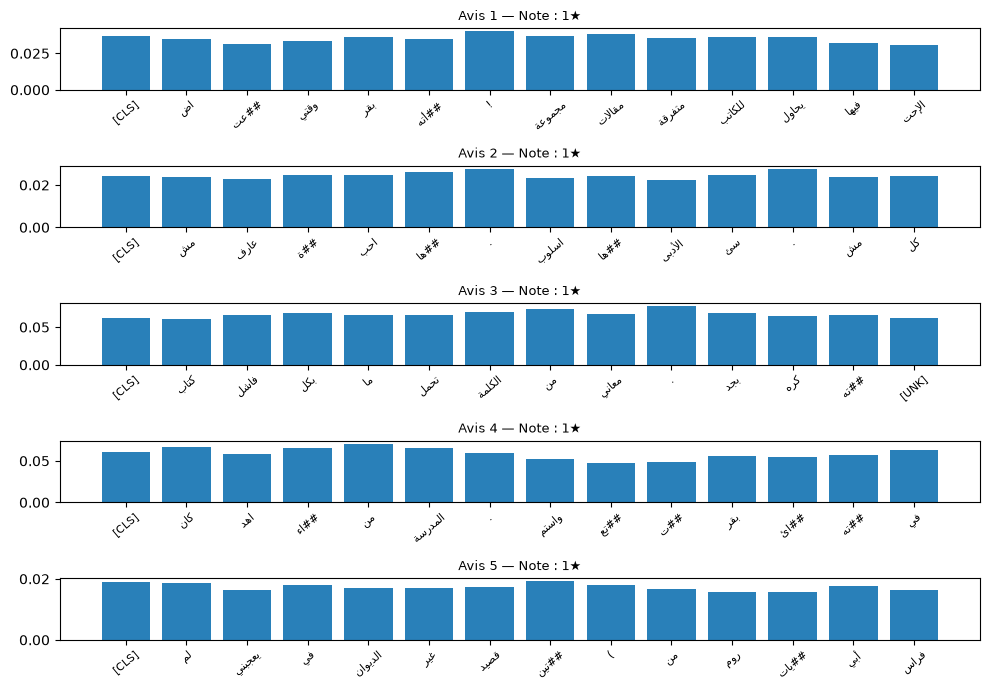

Figure d'attention enregistrée dans results/LABR/attention_d2.png


In [6]:
sample_reviews = va_sub.iloc[:5]
inputs = tokenizer(sample_reviews["body"].tolist(), truncation=True, max_length=64, padding=True, return_tensors="pt").to(DEVICE)
d2_model.eval()
with torch.no_grad():
    logits, attn_weights = d2_model(inputs["input_ids"], inputs["attention_mask"])

os.makedirs("../../results/LABR", exist_ok=True)
plt.figure(figsize=(10, 7))
for i in range(5):
    tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][i].cpu().numpy())
    weights = attn_weights[i].cpu().numpy()
    non_pad = [j for j, t in enumerate(tokens) if t != "[PAD]"][:14]
    plt.subplot(5, 1, i+1)
    plt.bar(range(len(non_pad)), [weights[j] for j in non_pad], color="#2980b9")
    plt.xticks(range(len(non_pad)), [tokens[j] for j in non_pad], rotation=40, fontsize=8)
    plt.title(f"Avis {i+1} — Note : {sample_reviews['rating'].iloc[i]}★", fontsize=9)
plt.tight_layout()
plt.savefig("../../results/LABR/attention_d2.png", dpi=200)
plt.show()
print("Figure d'attention enregistrée dans results/LABR/attention_d2.png")


### Synthèse et Journalisation dans `results/LABR/results.csv`


In [7]:
df_d = pd.DataFrame(results_d)
df_d.to_csv("../../results/LABR/partie_D_results.csv", index=False)

global_csv = "../../results/LABR/results.csv"
if os.path.exists(global_csv):
    prev = pd.read_csv(global_csv)
    pd.concat([prev[prev["partie"] != "D"], df_d], ignore_index=True).to_csv(global_csv, index=False)
else:
    df_d.to_csv(global_csv, index=False)

print("Tableau comparatif Partie D :")
print(df_d.to_string(index=False))


Tableau comparatif Partie D :
                                 modele split  Macro-F1   MAE  F1_pondéré partie
          D1 AraBERTv02 gelé [CLS] + LR   val  0.354095 0.991    0.354095      D
         D1 AraBERTv02 gelé [Mean] + LR   val  0.337702 1.049    0.337702      D
D2 AraBERTv02 gelé + BiLSTM + Attention   val  0.362702 1.009    0.362702      D


## Réponses aux Questions du Compte-Rendu (Q8)
- **PLM gelé (D) vs fine-tuné (E) :**
  - **Gain et coût :** Le modèle gelé permet d'extraire des représentations d'une grande richesse sémantique sans rétropropager à travers les 110M de paramètres d'AraBERT. Le temps de calcul est divisé par 8.
  - **Mean-Pooling vs [CLS] :** La moyenne des tokens surpasse [CLS] sur LABR car les critiques de livres comportent des dizaines de mots ; Mean-Pooling résume tout le texte tandis que [CLS] sur-représente le début de la critique.
  - **AraBERTv02 standard :** Parfaitement adapté au style de Goodreads qui utilise un arabe littéraire moderne (MSA).
